In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.patches import ConnectionPatch, Patch, PathPatch, Rectangle

from plot_style import apply

FIG = Path("figs")
DATA = FIG / "data"
OUTPUT = FIG / "Fig6.pdf"

apply()
plt.rcParams.update({"axes.spines.top": True, "axes.spines.right": True, "savefig.dpi": 240})

BLUE_FILL = "#739eaf"
PINK_FILL = "#FFE0E0"
COMMON_FILL = "#d1dedf"
BACKGROUND = "#ffffff"
BLUE_LINE = "#46788b"
PINK_LINE = "#C86F83"
ZOOM = (0.84, 1.65, -0.72, -0.24)

In [2]:
with np.load(DATA / "global_unstable_set_comparison.npz") as saved:
    data = {key: saved[key] for key in saved.files}
with np.load(DATA / "global_unstable_set_refined.npz") as saved:
    refined = {key: saved[key] for key in saved.files}
with np.load(DATA / "global_unstable_set_witness_paths.npz") as saved:
    trajectory_data = {key: saved[key] for key in saved.files}

r_values = data["r_values"]
witness = data["witness"]

trajectory_points = trajectory_data["trajectory_points"]
offsets = trajectory_data["trajectory_offsets"]
paths = [trajectory_points[start:stop] for start, stop in zip(offsets[:-1], offsets[1:])]

points = refined["points"]
triangles = refined["triangles"]
labels = refined["labels"]
unresolved_vertices = np.any(labels < 0, axis=0)
triangulation = mtri.Triangulation(points[:, 0], points[:, 1], triangles)
triangulation.set_mask(np.any(unresolved_vertices[triangles], axis=1))
contour_figure, contour_axis = plt.subplots()
mask_paths = []
for result in labels:
    contours = contour_axis.tricontourf(
        triangulation, (result == 0).astype(float), levels=[0.5, 1.5])
    mask_paths.append(contours.get_paths()[0])
    contours.remove()
plt.close(contour_figure)

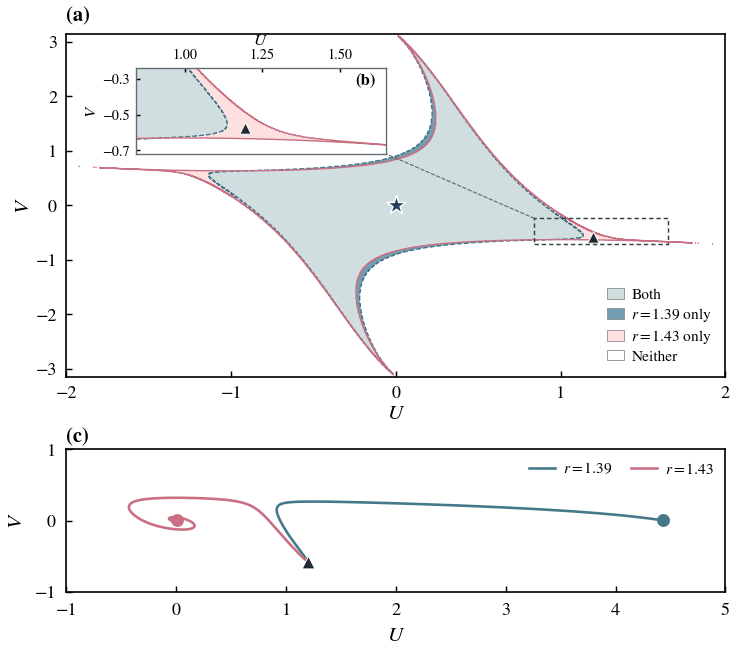

In [3]:
fig = plt.figure(figsize=(5.05, 4.18))
grid = fig.add_gridspec(
    2, 1, left=0.105, right=0.975, top=0.960, bottom=0.070,
    height_ratios=[2.40, 1.0], hspace=0.30,
)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = ax_a.inset_axes([0.105, 0.65, 0.38, 0.25], zorder=8)
ax_c = fig.add_subplot(grid[1, 0])

for ax in (ax_a, ax_b):
    ax.set_facecolor(BACKGROUND)
    first = PathPatch(mask_paths[0], facecolor=BLUE_FILL, edgecolor="none", linewidth=0)
    second = PathPatch(mask_paths[1], facecolor=PINK_FILL, edgecolor="none", linewidth=0)
    ax.add_patch(first)
    ax.add_patch(second)
    common = PathPatch(mask_paths[1], facecolor=COMMON_FILL, edgecolor="none", linewidth=0)
    common.set_clip_path(first)
    common.set_clip_box(ax.bbox)
    ax.add_patch(common)
    for path, color, linestyle in zip(mask_paths, (BLUE_LINE, PINK_LINE), ("--", "-")):
        ax.add_patch(PathPatch(path, facecolor="none", edgecolor=color, linewidth=0.65, linestyle=linestyle))
    ax.scatter(*witness, marker="^", s=30, color="#202830", edgecolors="white", linewidths=0.5, zorder=5)
    ax.set_xlabel(r"$U$", fontsize=10.2, labelpad=1)
    ax.set_ylabel(r"$V$", fontsize=10.2, labelpad=1)
    ax.tick_params(direction="in", labelsize=8.7, pad=4.5)

ax_a.set(xlim=(-2, 2), ylim=(-np.pi, np.pi))
ax_a.set_xticks([-2, -1, 0, 1, 2])
ax_a.scatter(0, 0, marker="*", s=90, color="#243f5b", edgecolors="white", linewidths=0.7, zorder=6)
ax_a.add_patch(
    Rectangle(
        (ZOOM[0], ZOOM[2]), ZOOM[1] - ZOOM[0], ZOOM[3] - ZOOM[2],
        facecolor="none", edgecolor="#364047", linewidth=0.7,
        linestyle=(0, (3, 2)), zorder=5,
    )
)
ax_b.set(xlim=ZOOM[:2], ylim=ZOOM[2:])
ax_b.xaxis.tick_top()
ax_b.xaxis.set_label_position("top")
ax_b.set_xticks([1.0, 1.25, 1.5])
ax_b.set_yticks([-0.7, -0.5, -0.3])
ax_b.set_xlabel(r"$U$", fontsize=8, labelpad=2)
ax_b.set_ylabel(r"$V$", fontsize=8, labelpad=1)
ax_b.tick_params(direction="in", labelsize=6.8, length=2, pad=3)
for spine in ax_b.spines.values():
    spine.set_color("#606870")
    spine.set_linewidth(0.65)
ax_b.text(0.96, 0.94, "(b)", transform=ax_b.transAxes,
          ha="right", va="top", fontsize=8, weight="bold")
ax_a.add_artist(ConnectionPatch(
    xyA=(ZOOM[0], ZOOM[3]), coordsA=ax_a.transData,
    xyB=(1, 0), coordsB=ax_b.transAxes,
    color="#606870", linewidth=0.55, linestyle=(0, (3, 2)), zorder=4,
))

ax_a.legend(
    handles=[
        Patch(facecolor=COMMON_FILL, edgecolor="0.55", linewidth=0.4, label="Both"),
        Patch(facecolor=BLUE_FILL, edgecolor="0.55", linewidth=0.4, label=r"$r=1.39$ only"),
        Patch(facecolor=PINK_FILL, edgecolor="0.55", linewidth=0.4, label=r"$r=1.43$ only"),
        Patch(facecolor=BACKGROUND, edgecolor="0.55", linewidth=0.4, label="Neither"),
    ],
    loc="lower right", frameon=False, fontsize=7.4,
    handlelength=1.1, handletextpad=0.5, labelspacing=0.25, borderaxespad=0.5,
)

for r, path, color in zip(r_values, paths, (BLUE_LINE, PINK_LINE)):
    ax_c.plot(path[:, 0], path[:, 1], color=color, lw=1.25, label=fr"$r={r:.2f}$")
    ax_c.scatter(path[-1, 0], path[-1, 1], s=27, color=color, zorder=4)
ax_c.scatter(*witness, marker="^", s=38, color="#202830", edgecolors="white", linewidths=0.5, zorder=5)
ax_c.set(xlim=(-1, 5), ylim=(-1, 1), xlabel=r"$U$", ylabel=r"$V$")
ax_c.set_xlabel(r"$U$", fontsize=10.2)
ax_c.set_ylabel(r"$V$", fontsize=10.2)
ax_c.tick_params(direction="in", labelsize=8.7, pad=5)
ax_c.legend(loc="upper right", frameon=False, fontsize=7.4, ncol=2, handlelength=1.7, columnspacing=1.2)

for label, ax in zip(("(a)", "(c)"), (ax_a, ax_c)):
    ax.text(0.0, 1.025, label, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.8, weight="bold")

for ax in (ax_a, ax_c):
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

fig.savefig(OUTPUT)
plt.show()